# Large cells on the sparse backend

In this tutorial you compute the bands, the density of states (DOS) and the Boltzmann transport tensors of a 16-atom Si supercell on the sparse backend of PAOFLOW, the route for cells whose Hamiltonian on the k-mesh does not fit in memory. You switch the workflow of the [bands and DOS tutorial](tutorial01.ipynb) to the sparse backend, build the supercell by doubling the two-atom cell along each lattice vector, compute its bands, then the DOS and the transport tensors in one loop over the k-mesh, and check the result against the dense pipeline of the bands and DOS tutorial on the two-atom cell. The physics of each property remains that of Tutorials 01 and 02. What changes is how the Hamiltonian is stored and diagonalised, and with it come two approximations, a truncated real-space Hamiltonian and a limited set of solved states, derived in [Large cells: truncated hoppings, doubled cells and partial spectra](../theory/large-cells.md). The methods are the constructor {py:class}`~PAOFLOW.PAOFLOW.PAOFLOW` with `sparse=True`, {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.doubling_Hamiltonian`, the `fused()` block of the backend, {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.save_sparse_hamiltonian` and {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.load_sparse_hamiltonian`.

**What you will compute**

- How the memory of the dense pipeline grows with the size of the cell, which decides when to switch.
- The PAO Hamiltonian as a list of hoppings, truncated at a neighbour shell, and a bound on the error of its eigenvalues.
- A $2\times2\times2$ Si supercell, how its Hamiltonian grows on each pipeline, and its bands folded into a smaller Brillouin zone.
- The DOS and transport tensors of the supercell from one loop over the k-mesh, and the states that loop solves.
- A comparison with the dense pipeline that separates the error of the backend from that of the truncation.

:::{tip}
This page is built on the case [`si_sparse_backend`](https://github.com/marcobn/PAOFLOW/tree/develop/examples/cases/si_sparse_backend): open it in PAOFLOW Studio with *Examples…* → `si_sparse_backend`, or copy it with `paoflow-gen --example si_sparse_backend`. The `main.py` of the case makes the PAOFLOW calls of this page in order, without the text, the plots and the checks, so that you can run the workflow as a script, for example on a cluster. To change the truncation or the size of the supercell, or start a large cell of your own from this workflow, {download}`download this notebook <tutorial04.ipynb>`. Its first code cell downloads the file `si_sparse_backend-v1.tar.gz` of the release [case-data](https://github.com/marcobn/PAOFLOW/releases/tag/case-data), and extracts `silicon.save` next to the notebook, unless it is already there; on a machine without internet access, download it by hand and extract it there with `tar xzf si_sparse_backend-v1.tar.gz`. The notebook runs in about two minutes as a single process. This tutorial assumes the [bands and DOS tutorial](tutorial01.ipynb) and, for the transport tensors, the [Boltzmann transport tutorial](tutorial02.ipynb).
:::

## Required input

`silicon.save` is the output directory of the three QE runs of the case on bulk Si: `scf.in`, the self-consistent run, `nscf.in`, the non-self-consistent run on a $12\times12\times12$ grid, and `proj.in`, the run of `projwfc.x` that projects the Kohn–Sham states onto the atomic orbitals. PAOFLOW reads three files from it:

- `data-file-schema.xml`: the crystal structure, the k-point grid and the Kohn–Sham eigenvalues
- `atomic_proj.xml`: the projections of the Kohn–Sham states onto the atomic orbitals, written by `projwfc.x`
- `Si.pbe-tm-new-gipaw-v2.1.UPF`: the pseudopotential, whose $3s$, $3p$ and $3d$ orbitals form the PAO basis

If you would like to create the `.save` directory yourself instead of downloading it, run the inputs of the case in its folder, in order:

```bash
mpirun -np 4 pw.x -in scf.in > scf.out
mpirun -np 4 pw.x -in nscf.in > nscf.out
mpirun -np 4 projwfc.x -in proj.in > proj.out
```

To run this notebook on your own calculation, set `savedir` in the next cell to its `.save` directory; the download then does not run.

In [1]:
from pathlib import Path
from tarfile import open as open_tar
from urllib.request import urlretrieve

savedir = 'silicon.save'
outputdir = 'output'

# fetch the DFT output of the case from the release named in the tip, unless it is here already
if not Path(savedir).is_dir():
    archive = Path('si_sparse_backend-v1.tar.gz')
    if not archive.is_file():
        urlretrieve(
            'https://github.com/marcobn/PAOFLOW/releases/download/'
            'case-data/si_sparse_backend-v1.tar.gz',
            archive,
        )
    with open_tar(archive, 'r:gz') as tar:
        members = [m for m in tar.getmembers() if m.name.startswith('silicon.save/')]
        tar.extractall(members=members, filter='data')

## When the dense pipeline runs out of memory

You switch to the sparse backend when the arrays of the dense pipeline do not fit in the memory of a node. The dense pipeline keeps three arrays on the interpolated k-mesh: the Hamiltonian $\tilde H(\mathbf{k})$, its gradient with three components, and the eigenvectors. Each component holds $N_\mathrm{mesh}\, n_\mathrm{awf}^2$ complex numbers of 16 bytes, where $N_\mathrm{mesh}$ is the number of k-points of the mesh and $n_\mathrm{awf}$ the number of PAOs in the cell, so together they take

$$
M_\mathrm{dense} = 5 \times 16\, N_\mathrm{mesh}\, n_\mathrm{awf}^2 \ \mathrm{bytes}.
$$

In a supercell of $N$ primitive cells, $n_\mathrm{awf}$ grows as $N$, while the number of k-points that samples the Brillouin zone with the same density falls as $1/N$, so $M_\mathrm{dense}$ grows as $N$. The cell below evaluates it for Si supercells at the k-point density of the $24\times24\times24$ mesh of the bands and DOS tutorial.

In [2]:
def dense_memory_gb(n_awf, n_mesh):
    """Memory of H(k), its three gradient components and the eigenvectors on the mesh (GB)."""
    return 5 * 16 * n_mesh * n_awf**2 / 1e9


print(' atoms  orbitals   mesh  memory (GB)')
for doublings, mesh in [(0, 24), (1, 12), (2, 6), (3, 3)]:
    cells = 8**doublings  # each doubling along the three lattice vectors multiplies the cell by 8
    n_awf = 18 * cells  # two Si atoms per primitive cell, nine PAOs per atom
    print(f'{2 * cells:6d} {n_awf:9d}  {mesh:2d}^3 {dense_memory_gb(n_awf, mesh**3):12.1f}')

 atoms  orbitals   mesh  memory (GB)
     2        18  24^3          0.4
    16       144  12^3          2.9
   128      1152   6^3         22.9
  1024      9216   3^3        183.5


Each doubling of the cell along the three lattice vectors multiplies the memory by 8: 0.4 GB for the two-atom cell, 2.9 GB for 16 atoms, 23 GB for 128 atoms and 184 GB for 1024 atoms. Defect supercells, slabs, interfaces and heterostructures therefore exhaust the memory of a node. To avoid this, the sparse backend never forms these arrays. Instead, it stores $H(\mathbf{R})$ as a list of hoppings, builds $\tilde H(\mathbf{k})$ at one k-point at a time, and discards it and its eigenvectors before the next ([The Hamiltonian as a list of hoppings](../theory/large-cells.md#the-hamiltonian-as-a-list-of-hoppings)).

Use the dense pipeline whenever it fits in memory, because it has every PAOFLOW method and needs no truncation. This tutorial uses the 16-atom cell, which still fits, so that you can compare the two pipelines below.

## Switching the script to the sparse backend

You switch the script with two arguments of the constructor: `sparse=True`, and the options of the backend in the dictionary `sparse_config`, all listed in {py:class}`~PAOFLOW.sparse.config.SparseConfig`. Every other method keeps the name and arguments it has on the dense pipeline.

The first three calls run as on the dense pipeline, on the DFT cell. `read_atomic_proj_QE()` reads the projections that `projwfc.x` wrote, in place of the projections PAOFLOW computes itself in the bands and DOS tutorial; both routes work on the sparse backend. At the end of `pao_hamiltonian()` the backend converts $H_{\alpha\beta}(\mathbf{R})$ to a list of hoppings, one entry per pair of orbitals $\alpha\beta$ and lattice vector $\mathbf{R}$, and drops the hoppings on bonds longer than the 36th neighbour shell, the set of bonds of the 36th distinct length. This truncation is the first approximation of the backend: to first order, each eigenvalue moves by the expectation value of the dropped hoppings in its state, with the opposite sign, an error set by how fast the hoppings decay with distance ([Error of the eigenvalues](../theory/large-cells.md#error-of-the-eigenvalues)). A cutoff on the bond length keeps or drops whole shells, so it keeps the symmetry of the crystal ([Truncation and crystal symmetry](../theory/large-cells.md#truncation-and-crystal-symmetry)). Its reach is limited by the DFT k-grid, $12\times12\times12$ here, whose lattice vectors $\mathbf{R}$ represent each bond by one element only up to half the smallest interplanar spacing of the $12\times12\times12$ supercell; a longer cutoff needs a denser DFT grid ([The range limit of the DFT grid](../theory/large-cells.md#the-range-limit-of-the-dft-grid)). [How to choose the truncation of the sparse Hamiltonian](../howtos/sparse-truncation.md) shows how to choose the cutoff for your material. The truncation is applied once, here, and stays fixed for the rest of the run.

The last call writes the truncated $H(\mathbf{R})$ of the two-atom cell to a file for the check against the dense pipeline. It saves the list of the DFT cell, so it comes before the doubling.

In [3]:
from PAOFLOW import PAOFLOW

paoflow = PAOFLOW.PAOFLOW(
    savedir=savedir,
    outputdir=outputdir,
    smearing='gauss',
    sparse=True,
    sparse_config={'bond_order': 36},
)
paoflow.read_atomic_proj_QE()
paoflow.projectability()
paoflow.pao_hamiltonian()  # H(R) becomes a list of hoppings, truncated at the 36th shell
paoflow.save_sparse_hamiltonian(
    'silicon_bo36.npz'
)  # to outputdir, for the check against the dense pipeline


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.041 sec


Projectability in:                          5.986 sec


Building Hks in:                            1.880 sec


k -> R in:                                  0.043 sec


Sparse conversion in:                       0.139 sec


save_sparse_hamiltonian in:                 0.577 sec


In [4]:
import re
from pathlib import Path


def show_log(title):
    """Print one section of sparse.log, the log the sparse backend writes to outputdir."""
    text = Path(outputdir, 'sparse.log').read_text()
    print(re.search(rf'^{re.escape(title)}\n.*?(?=\n\n|\Z)', text, re.M | re.S).group(0))


show_log('Hamiltonian (base cell)')

Hamiltonian (base cell)
-----------------------
  cutoff radius (Bohr)   32.129  (bond length of neighbour shell 36)
  hopping threshold (eV) none
  orbitals (nawf)        18
  R vectors              1728
  bonds kept             0.153M of 0.56M  (27.3%)
  bond list (MB)         7.6
  dense H(R) (MB)        8.5
  max eigenvalue shift from truncation (eV)  4.11


The backend writes this log, `sparse.log`, to the output directory, one section per step. The cutoff of shell 36 lies at 32.129 Bohr, and of the 0.56 million elements of $H(\mathbf{R})$ on the 1728 lattice vectors of the DFT grid the backend kept 27.3%, 7.6 MB against 8.5 MB for the dense array. For the two-atom cell the saving is small; what matters is how the two grow with the cell, which the doubled cell below shows. The last line, 4.11 eV, is a rigorous bound on the shift of any eigenvalue at any k-point: the largest sum of the magnitudes of the dropped hoppings of one orbital ([A bound on the eigenvalue shift](../theory/large-cells.md#a-bound-on-the-eigenvalue-shift)). In the actual shifts the Bloch phases of the dropped hoppings partly cancel, so the bound is loose, and the truncation how-to measures the shifts on the bands instead.

## A 16-atom cell by doubling

`doubling_Hamiltonian(1, 1, 1)` doubles the cell along each of the three lattice vectors, which gives a $2\times2\times2$ supercell of 16 atoms and 144 PAOs. The arguments count doublings, not copies: `doubling_Hamiltonian(2, 2, 2)` doubles twice along each vector, a supercell of 64 primitive cells. It builds $H(\mathbf{R})$ of the supercell by placing the hoppings of the two-atom cell between the copies of each orbital, so it needs no new DFT calculation and adds no approximation: the supercell is the same crystal, and its bands are those of the two-atom cell folded into its eight times smaller Brillouin zone ([Cell doubling](../theory/large-cells.md#cell-doubling)). In this tutorial the supercell stands in for a large cell from a DFT calculation, such as a defect supercell or a slab, whose $H(\mathbf{R})$ you would build with the first three calls of [Switching the script to the sparse backend](#switching-the-script-to-the-sparse-backend).

In [5]:
paoflow.doubling_Hamiltonian(1, 1, 1)  # before bands() and every property
show_log('Doubling (nx, ny, nz = 1, 1, 1)')

doubling_Hamiltonian in:                    6.610 sec


Doubling (nx, ny, nz = 1, 1, 1)
-------------------------------
  cells                  8  (2^3)
  orbitals (nawf)        18 -> 144
  bonds                  0.153M -> 1.22M
  peak memory per rank (GB)  0.52
  available per rank (GB)  41.05  (80% of MemAvailable 51.3 GB, shared by 1 rank on this node)
  steady memory per rank (GB)  0.03
  dense H(k) per k-point (GB)  0.00
  H(k) solver after doubling  dense (LAPACK)
  bonds after doubling   1.22M
  bond list after doubling (MB)  60.7
  max eigenvalue shift from truncation (eV)  4.11



The list grows by a factor of 8, from 0.153 to 1.22 million hoppings (60.7 MB), in proportion to the number of atoms, because each atom keeps its bonds. A dense $H(\mathbf{R})$ on the same $\mathbf{R}$ grid holds every pair of orbitals, so it grows by a factor of 64, to 64 times the 8.5 MB of the two-atom cell. Every bond keeps its length, so the truncation and its bound of 4.11 eV carry over unchanged ([The doubled Hamiltonian](../theory/large-cells.md#the-doubled-hamiltonian)). The log also gives the memory the doubling needs at its peak, 0.52 GB per MPI rank, against the memory available to each rank. When the peak exceeds it, the backend warns and continues; in that case double fewer times, truncate more, or start fewer ranks per node, because every MPI rank holds the whole list of hoppings.

`bands()` then gives the bands of the supercell along the high-symmetry path of its Brillouin zone. The supercell is an fcc crystal with lattice vectors twice as long, so `ibrav=2` still names its path, and each band of the two-atom cell appears eight times, folded from the eight k-points of the larger zone that differ by a reciprocal lattice vector of the supercell ([Band folding](../theory/large-cells.md#band-folding)). `bands()` has no energy range, so on the sparse backend it solves every band the PAO basis represents, as the dense pipeline does.

In [6]:
paoflow.bands(ibrav=2, nk=500)
show_log('Solve window (bands)')

Bands in:                                   9.243 sec


Solve window (bands)
--------------------
  properties             none
  window (eV)            bottom of the spectrum to 6.961
  bands per k-point      72 of 144  (all 72 projectable bands)


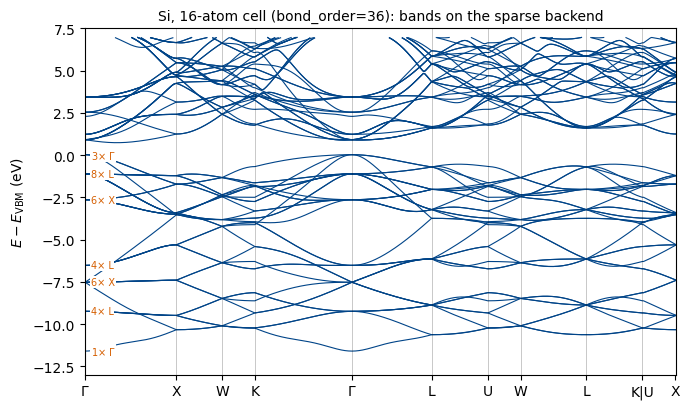

bands per k-point: 72, valence bands: 32


In [7]:
import matplotlib.pyplot as plt
import numpy as np

bands = np.loadtxt('output/bands_0.dat')[:, 1:]  # one row per k-point; NaN above the solved states
labels = open('output/kpath_points.txt').read().split('\n\n')[0].split()
ticks, names = [0], []
for name, n in zip(labels[0::2], labels[1::2]):
    name = name.replace('gG', r'$\Gamma$')
    names.append(name if len(names) < len(ticks) else f'{names.pop()}|{name}')  # a jump: K|U
    if int(n) > 0:
        ticks.append(ticks[-1] + int(n))

fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.plot(bands, color='#004488', lw=0.8)
for x in ticks[1:-1]:
    ax.axvline(x, color='#000000', lw=0.5, alpha=0.3)
# the valence states at Gamma of the supercell, with the k-point of the 2-atom cell they come from
levels, counts = np.unique(np.round(bands[0, :32], 2), return_counts=True)
origin = {1: r'$\Gamma$', 3: r'$\Gamma$', 4: 'L', 6: 'X', 8: 'L'}
for energy, count in zip(levels, counts):
    ax.annotate(
        f'{count}× {origin[count]}',
        (0, energy),
        xytext=(4, 0),
        textcoords='offset points',
        fontsize=7,
        va='center',
        color='#D55E00',
        bbox={'boxstyle': 'square,pad=0.1', 'facecolor': 'white', 'edgecolor': 'none'},
    )
ax.set_xticks(ticks[: len(names)], names)
ax.set_xlim(0, len(bands) - 1)
ax.set_ylim(-13.0, 7.5)
ax.set_ylabel(r'$E - E_\mathrm{VBM}$ (eV)')
ax.set_title('Si, 16-atom cell (bond_order=36): bands on the sparse backend', fontsize=10)
fig.tight_layout()
plt.show()
print(f'bands per k-point: {bands.shape[1]}, valence bands: 32')

The supercell has 72 bands below the PAO shift, eight times the 9 of the two-atom cell, and 32 of them are valence bands, eight copies of the four of Si. At $\Gamma$ of the supercell the valence states are those of the two-atom cell at $\Gamma$ and at the k-points that fold onto it, the four L points and the three X points, as the labels mark: the bottom of the valence band at $\Gamma$ ($-11.60$ eV) once, the lowest L state ($-9.25$ eV) four times, the lowest X pair ($-7.52$ eV) six times, up to the threefold valence-band maximum. These degeneracies are the check that the doubled Hamiltonian describes the same crystal. The bands end at 6.96 eV, the PAO shift minus a margin, above which the backend solves no states ([The upper limit set by the PAO shift](../howtos/sparse-states.md#the-upper-limit-set-by-the-pao-shift)).

## DOS and transport of the supercell in one pass

You now compute the DOS and the transport tensors of the supercell. The Brillouin zone of the supercell is eight times smaller than that of the two-atom cell, so a $12\times12\times12$ mesh samples it with the density of the $24\times24\times24$ mesh of the bands and DOS tutorial; folded back into the zone of the two-atom cell, it holds the same k-points ([What doubling changes](../theory/large-cells.md#what-doubling-changes)). On the sparse backend `interpolated_hamiltonian()` only records this mesh, because the list of hoppings gives $\tilde H(\mathbf{k})$ at any $\mathbf{k}$.

The script has no `pao_eigh()`, `gradient_and_momenta()` or `adaptive_smearing()`, because on the sparse backend these calls compute nothing. On the dense pipeline, `pao_eigh()` diagonalises $\tilde H(\mathbf{k})$ at every k-point and keeps all eigenvectors for the steps that follow, which is the array a large cell cannot afford. The sparse backend instead diagonalises one k-point at a time, computes there everything the properties of the script need (eigenvalues, band velocities, adaptive smearing widths, projections for the projected DOS), and discards the eigenvectors before the next k-point. One such loop over all k-points of the mesh is called a pass. Since only the properties tell the pass what to compute, the pass runs when a property needs it, and the three methods only store their arguments for it; a script that keeps their defaults leaves them out.

The calls inside the `fused()` block are collected, and one pass serves all of them when the block ends. Put all properties of the run in this block, for two reasons. After a pass only the eigenvalues and band velocities stay in memory, so a property that needs the eigenvectors, such as `dielectric_tensor()`, called after the pass, starts a second pass that repeats every diagonalisation. And a pass solves only the states up to the highest energy range among its properties (see the output below), so a property called later with a higher range would find states missing; the run then stops with an error instead of returning an incomplete result.

For a cell with many atoms, pass `do_pdos=False` to `dos()` unless you need the projected DOS, because by default it writes one file per orbital, thousands of files for a large supercell.

In [8]:
paoflow.interpolated_hamiltonian(nfft1=12, nfft2=12, nfft3=12)  # the density of 24^3 for 2 atoms
with paoflow.sparse.fused():
    paoflow.dos(emin=-12.0, emax=2.2, ne=1000, do_pdos=False)
    paoflow.transport(emin=-12.0, emax=2.2)
paoflow.finish_execution()
show_log('Solve window (mesh pass 1)')

R -> k with Zero Padding in:                1.724 sec


Sparse mesh pass in:                       69.306 sec


DoS in:                                     1.788 sec


Transport in:                               2.048 sec


Total CPU time =                           99.402 sec
Solve window (mesh pass 1)
--------------------------
  properties             dos, transport
  probe                  16 k-points; largest adaptive width 0.674 eV (afac 0.70, k spacing 0.0392 1/Bohr)
  smearing margin (eV)   2.694  (4 x the largest adaptive width)
  thermal margin (eV)    0.259 at 300 K  (10 kT)
  dos range (eV)         [-12.000, 2.200]  + smearing margin
  transport range (eV)   [-12.000, 2.200]  + thermal margin at 300 K
  window (eV)            bottom of the spectrum to 4.894
  bands per k-point      62 of 144  (54 states below the window top at the probe points, padded to 62)


The log shows the second approximation of the backend: a pass solves the states from the bottom of the spectrum up to the highest energy range among its properties plus a margin, a range the log calls the solve window ([The states of a pass](../theory/large-cells.md#the-states-of-a-pass)). Each margin is the reach of the weight a property gives a state beyond its range. For the DOS it is four times the largest adaptive smearing width, 2.694 eV, because a state of width $\sigma$ still contributes to the DOS about $4\sigma$ from its energy ([Smearing tails](../theory/large-cells.md#smearing-tails)). For transport it is $10\,k_BT$ at the highest temperature, 0.259 eV at 300 K, the reach of the Fermi window ([The Fermi window](../theory/large-cells.md#the-fermi-window)). Both ranges end at `emax` = 2.2 eV, so the DOS sets the window, which ends at 4.894 eV, and the pass solves 62 of the 144 states at each k-point, where the dense pipeline would solve all of them. With 62 of 144 states each $\tilde H(\mathbf{k})$ is still diagonalised in full, one k-point at a time ([The eigensolver of the sparse backend](../../internals/sparse-eigensolver.md)). [How to choose which states the sparse backend solves](../howtos/sparse-states.md) explains the properties that need every state and the two options that change the states solved.

The warning about adaptive widths below the energy grid spacing concerns the DOS on this mesh and is the same as on the dense pipeline; [Band velocities and adaptive smearing](tutorial01.ipynb#band-velocities-and-adaptive-smearing) in the bands and DOS tutorial explains the `min_width` that removes it, which you pass to `adaptive_smearing()` before the `fused()` block.

**Output:** `output/dosdk_0.dat` holds the DOS of the 16-atom cell, and `sigmagauss_0.dat`, `Seebeckgauss_0.dat`, `kappagauss_0.dat` and `PFgauss_0.dat` the transport tensors, in the format of Tutorials 01 and 02.

## Checking the result against the dense pipeline

You check the backend by computing the same properties on the dense pipeline of the bands and DOS tutorial, for the two-atom cell, from the truncated $H(\mathbf{R})$ saved when you switched to the sparse backend. Both runs then share the truncation, so any difference comes from the sparse backend itself: the folding into the supercell and the limited set of solved states. The truncation error is a separate question, which you test by varying `bond_order` as the [truncation how-to](../howtos/sparse-truncation.md) shows.

With `restart=True` the constructor reads no DFT data, and `load_sparse_hamiltonian()` takes the place of `read_atomic_proj_QE()`, `projectability()` and `pao_hamiltonian()`, so this run needs neither `silicon.save` nor the projections. The calls that follow are those of the bands and DOS tutorial.

In [9]:
dense = PAOFLOW.PAOFLOW(outputdir='output_dense', restart=True, smearing='gauss')
dense.load_sparse_hamiltonian('output/silicon_bo36.npz')  # replaces the first three steps
dense.interpolated_hamiltonian()
dense.pao_eigh()
dense.gradient_and_momenta()
dense.adaptive_smearing()
dense.dos(emin=-12.0, emax=2.2, ne=1000, do_pdos=False)
dense.transport(emin=-12.0, emax=2.2)
dense.finish_execution()


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Run starting from Restart data.
Initialization in:                          0.000 sec


Loaded truncated Hamiltonian from output/silicon_bo36.npz
  152766 bonds, threshold = 0.0e+00 eV, bond_order = 36 (r_c = 32.129 Bohr), eig_bound = 4.111e+00 eV
load_sparse_hamiltonian in:                 0.082 sec


New estimated maximum array size: 0.86 GBytes
R -> k with Zero Padding in:                0.185 sec


Eigenvalues in:                             1.182 sec


Gradient in:                                1.246 sec


Momenta in:                                 0.647 sec


Adaptive Smearing in:                       0.164 sec


DoS (Adaptive Smearing) in:                 2.428 sec


Transport in:                               2.263 sec


Total CPU time =                            8.202 sec


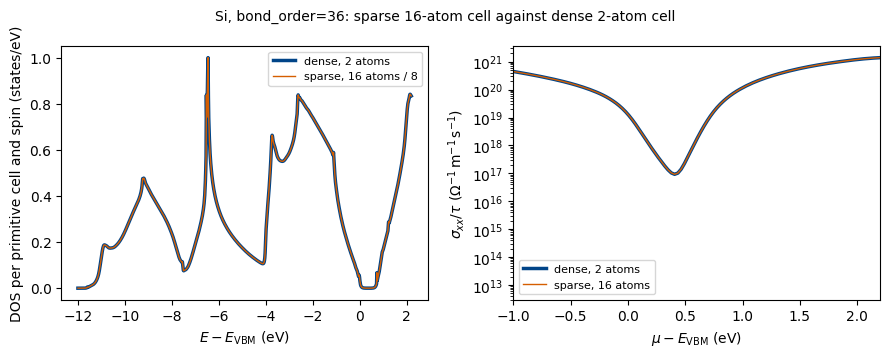

largest |DOS difference| / largest DOS: 3.3e-07
largest relative sigma_xx difference where sigma_xx > 1e-3 of its maximum: 4.4e-06


In [10]:
import matplotlib.pyplot as plt
import numpy as np

energy, dos_cell = np.loadtxt('output/dosdk_0.dat', unpack=True)
_, dos_dense = np.loadtxt('output_dense/dosdk_0.dat', unpack=True)
dos_sparse = dos_cell / 8  # the 16-atom cell holds eight primitive cells
sigma_sparse = np.loadtxt('output/sigmagauss_0.dat')
sigma_dense = np.loadtxt('output_dense/sigmagauss_0.dat')
mu = sigma_dense[:, 1]

fig, (left, right) = plt.subplots(1, 2, figsize=(9.0, 3.6))
left.plot(energy, dos_dense, color='#004488', lw=2.5, label='dense, 2 atoms')
left.plot(energy, dos_sparse, color='#D55E00', lw=1.0, label='sparse, 16 atoms / 8')
left.set_xlabel(r'$E - E_\mathrm{VBM}$ (eV)')
left.set_ylabel('DOS per primitive cell and spin (states/eV)')
left.legend(fontsize=8)
right.semilogy(mu, sigma_dense[:, 2], color='#004488', lw=2.5, label='dense, 2 atoms')
right.semilogy(mu, sigma_sparse[:, 2], color='#D55E00', lw=1.0, label='sparse, 16 atoms')
right.set_xlim(-1.0, 2.2)
right.set_xlabel(r'$\mu - E_\mathrm{VBM}$ (eV)')
right.set_ylabel(r'$\sigma_{xx}/\tau$ ($\Omega^{-1}\,\mathrm{m}^{-1}\,\mathrm{s}^{-1}$)')
right.legend(fontsize=8)
fig.suptitle('Si, bond_order=36: sparse 16-atom cell against dense 2-atom cell', fontsize=10)
fig.tight_layout()
plt.show()

print(
    f'largest |DOS difference| / largest DOS: {np.abs(dos_sparse - dos_dense).max() / dos_dense.max():.1e}'
)
inside = sigma_dense[:, 2] > 1e-3 * sigma_dense[:, 2].max()
print(
    f'largest relative sigma_xx difference where sigma_xx > 1e-3 of its maximum: {np.max(np.abs(sigma_sparse[inside, 2] / sigma_dense[inside, 2] - 1)):.1e}'
)

The sparse run of the 16-atom cell reproduces the dense run of the two-atom cell. The figure compares the DOS per primitive cell (the DOS of the 16-atom cell divided by 8) and $\sigma_{xx}/\tau$ at 300 K, with energies relative to the VBM, and the curves lie on top of each other: the DOS differs by at most $3.3\times10^{-7}$ of its maximum, and $\sigma_{xx}/\tau$ by $4.4\times10^{-6}$ of its value wherever it exceeds $10^{-3}$ of its maximum. The folding into the supercell and the 62 solved states therefore lose nothing: with the same truncated Hamiltonian and the same k-point density, the sparse backend reproduces the dense pipeline.

On your own system, run this comparison on a smaller version of it, with fewer atoms or a coarser k-mesh, so that the dense run fits in memory. A larger difference than here points to a different truncation in the two runs, or to a solve window that ends too close to a property range; the second case is reported by a warning, which starts with `WARNING:` in the output of the run and in `sparse.log`. When the log reports the iterative solver (ARPACK) for $\tilde H(\mathbf{k})$, as on a large cell with a narrow window, also repeat the sparse run with `'hk_solver': 'dense'` in `sparse_config`, which diagonalises each $\tilde H(\mathbf{k})$ in full: a difference points to copies of degenerate states that the iterative solver missed ([The eigensolver of the sparse backend](../../internals/sparse-eigensolver.md)).

:::{tip}
To continue on the dense pipeline in the same run instead of through a file, call `to_dense()` directly after `pao_hamiltonian()`, before any doubling, interpolation or band calculation:

```python
paoflow.pao_hamiltonian()  # truncated with sparse_config
paoflow.to_dense()  # every later call on this object runs on the dense pipeline
```

The saved file is also how you restart a sparse run, because `restart_dump()` saves the arrays of the dense pipeline and not the list of hoppings: start the new run with `sparse=True` and `restart=True`, and load the file in place of the first three steps.
:::

## Other properties on the sparse backend

Every property in the table below is computed with the same call as on the dense pipeline, with the arguments documented in its API entry, for example {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.anomalous_Hall`. Add the call inside the `fused()` block of the DOS and transport pass, so that it shares the pass with the other properties. A property marked "all states" needs every state at each k-point, most of them because they sum over pairs of bands ([Properties that need every state](../theory/large-cells.md#properties-that-need-every-state)). Its pass therefore solves the full spectrum, which on a cell with more than 4096 orbitals stops with an error ([how-to](../howtos/sparse-states.md#properties-that-need-every-state)).

| group | methods |
| --- | --- |
| bands along a path | `bands`, `wave_function_projection`, `site_projected_bands` (all states), `berry_curvature` (all states), `topology` |
| densities and Fermi surface | `dos` (with PDOS), `density`, `fermi_surface`, `ipr`, `jdos` |
| textures | `spin_texture`, `orbital_texture` |
| transport and response | `transport` (all states with `do_hall=True`), `doping`, `conductivity`, `effective_mass` (all states), `dielectric_tensor`, `rashba_edelstein` |
| Berry phase and Hall | `berry_phase`, `anomalous_Hall`, `spin_Hall`, `orbital_Hall`, `linear_response` (all states) |
| operations on $H(\mathbf{R})$ of the DFT cell | `add_external_fields`, `adhoc_spin_orbit`, `j_to_lm_hamiltonian`, `cutting_Hamiltonian`, `write_Hamiltonian` |

The operations in the last row act on the DFT cell, so call them after `pao_hamiltonian()` and before any doubling or interpolation; those that change $H(\mathbf{R})$ truncate the result again with the same `sparse_config`.

Non-linear optics, ARPES, the Weyl-point search, the mirror Chern number, the position-dipole correction, and the phonon and electron–phonon workflows exist only on the dense pipeline. Called on the sparse backend, they stop with an error that gives the reason. On a cell that fits in memory, compute them on the dense pipeline from the truncated Hamiltonian, as in the previous step.

## Where to go next

- [Large cells: truncated hoppings, doubled cells and partial spectra](../theory/large-cells.md): the error and the symmetry of a truncation, the folding of the bands of a doubled cell, and which states each property needs.
- [How to choose the truncation of the sparse Hamiltonian](../howtos/sparse-truncation.md): `bond_order`, `rcut` and `hopping_threshold`, and how to converge them.
- [How to choose which states the sparse backend solves](../howtos/sparse-states.md): the solve window, `nev` and `interior_window`.
- [The eigensolver of the sparse backend](../../internals/sparse-eigensolver.md): how the states of one k-point are solved, and the limit `dense_n_max`.
- {py:class}`~PAOFLOW.sparse.config.SparseConfig`: every option of `sparse_config`, with its default.

In [11]:
from pathlib import Path

import numpy as np

log = Path('output/sparse.log').read_text()
bonds = re.search(r'^  bonds after doubling\s+(\S+)', log, re.M).group(1)
assert bonds == '1.22M', f'hoppings after doubling {bonds}'
mesh = log[log.index('Solve window (mesh pass 1)') :]
top = float(re.search(r'^  window \(eV\)\s+bottom of the spectrum to (\S+)', mesh, re.M).group(1))
nev = int(re.search(r'^  bands per k-point\s+(\d+) of 144', mesh, re.M).group(1))
assert abs(top - 4.894) < 1e-3 and nev == 62, f'solve window top {top} eV, {nev} states per k'

bands = np.loadtxt('output/bands_0.dat')[:, 1:]
levels, counts = np.unique(np.round(bands[0, :32], 2), return_counts=True)
assert list(counts) == [
    1,
    4,
    6,
    4,
    6,
    8,
    3,
], f'valence degeneracies at Gamma of the supercell {counts}'
assert np.allclose(
    levels[:3], [-11.60, -9.25, -7.52], atol=5e-3
), f'valence levels at Gamma {levels[:3]}'
assert bands.shape[1] == 72, f'{bands.shape[1]} bands on the path'

energy, dos_cell = np.loadtxt('output/dosdk_0.dat', unpack=True)
_, dos_dense = np.loadtxt('output_dense/dosdk_0.dat', unpack=True)
dos_error = np.abs(dos_cell / 8 - dos_dense).max() / dos_dense.max()
assert dos_error < 1e-6, f'DOS per primitive cell, sparse 16 atoms against dense: {dos_error:.1e}'
sigma_sparse = np.loadtxt('output/sigmagauss_0.dat')[:, 2]
sigma_dense = np.loadtxt('output_dense/sigmagauss_0.dat')[:, 2]
inside = sigma_dense > 1e-3 * sigma_dense.max()
sigma_error = np.abs(sigma_sparse[inside] / sigma_dense[inside] - 1).max()
assert sigma_error < 1e-5, f'sigma_xx/tau, sparse 16 atoms against dense: {sigma_error:.1e}'